# 04 Extreme Frequency Plots

In [16]:
%load_ext autoreload
%autoreload 2
    
import os
import sys
import pandas as pd
import xarray as xr
import numpy as np
from dask.distributed import Client
import warnings
warnings.filterwarnings('ignore')

from cdrmip_extremes import (
    utils, stats, io_disk, plotting
)
from cdrmip_extremes.configs import CDR_MODELS, PROC_DIR, FIG_DIR

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [7]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)

In [8]:
base = PROC_DIR / 'ScenarioMIP' / 'extremes'
varname = 'tas'

ext_data = {
    name: io_disk.load_nested(base / name, f"{varname}_{name}", order=CDR_MODELS)
    for name in ['exceedances_matching_median_multimodel',
                 'branch_differences_matching_median_multimodel',
                 'agreement_matching']
}

In [9]:
exceedances = ext_data['exceedances_matching_median_multimodel']
differences = ext_data['branch_differences_matching_median_multimodel']
agreement = ext_data['agreement_matching']

In [10]:
differences_union = {
    model: {
        expt: {
            ext_type: ds for ext_type, ds in ext_type_dt.items()
        } for expt, ext_type_dt in expt_dt.items()
    } for model, expt_dt in differences.items() if model in CDR_MODELS
}
exceedances_union = {
    model: {
        expt: {
            ext_type: ds for ext_type, ds in ext_type_dt.items()
        } for expt, ext_type_dt in expt_dt.items()
    } for model, expt_dt in exceedances.items() if model in CDR_MODELS
}

In [11]:
expt = 'ssp534-over'
agreement_union = {expt:{}}
for ext_type in ['cold','heat']:
    agreement_union[expt][ext_type] = stats.calc_agreement(
        { 
            model:differences_union[model][expt][ext_type] for model in differences_union.keys()
        }
    )

In [13]:
differences_union['multi_model_median'] = {
    expt: {
        ext_type: xr.concat(
            [differences_union[model][expt][ext_type] for model in differences_union.keys()],
            dim='model',
            compat='override',
            coords='minimal'
        ).median(dim='model') for ext_type in ['heat','cold']
    }
}
exceedances_union['multi_model_median'] = {
    expt: {
        ext_type: xr.concat(
            [exceedances_union[model][expt][ext_type] for model in exceedances_union.keys()],
            dim='model',
            compat='override',
            coords='minimal'
        ).median(dim='model') for ext_type in ['heat','cold']
    }
}

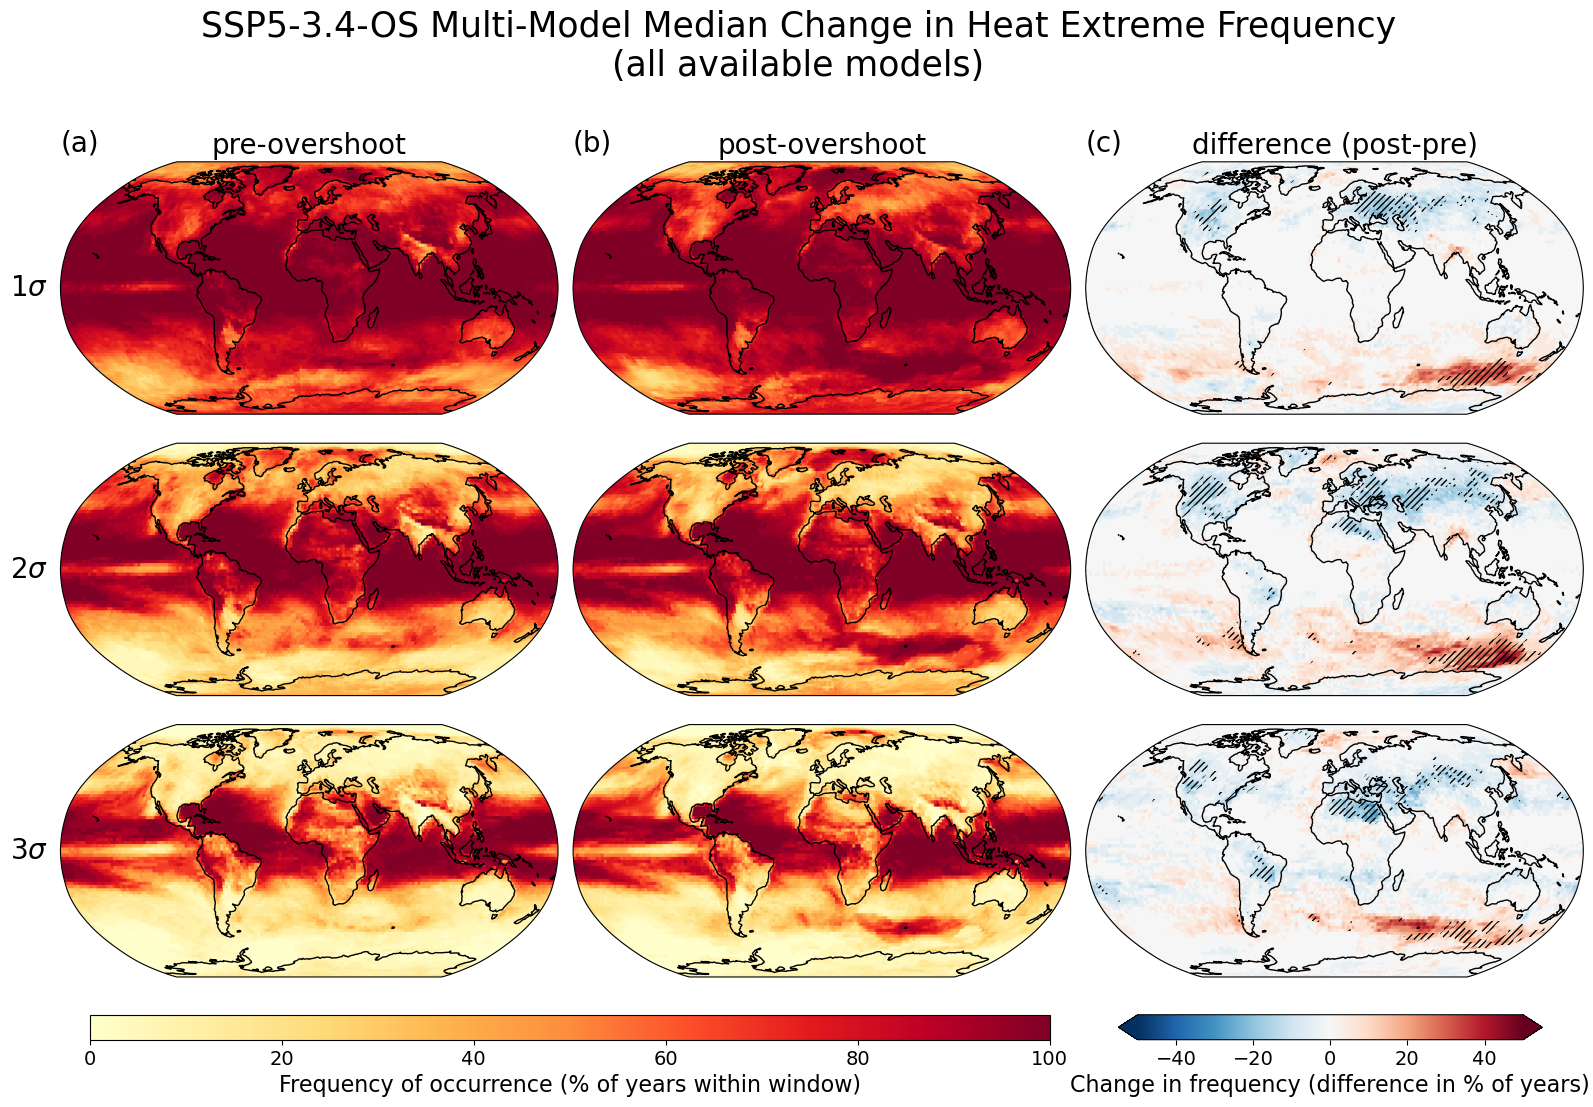

In [17]:
fig = plotting.plot_ext_freq(
    exceedances,
    differences,
    agreement, 
    model='multi_model_median',
    expt='ssp534-over',
    expt_name= 'SSP5-3.4-OS',
    ext_type='heat',
    gwl=None,
    period='equivalent',
    model_name = 'Multi-Model Median',
    suptitle = "SSP5-3.4-OS Multi-Model Median Change in Heat Extreme Frequency\n(all available models)",
    # fig_dir=FIG_DIR,
    # folder='supplementary',
    # file_name='figure_S18.jpg'
    
)

## Plot differences for each model

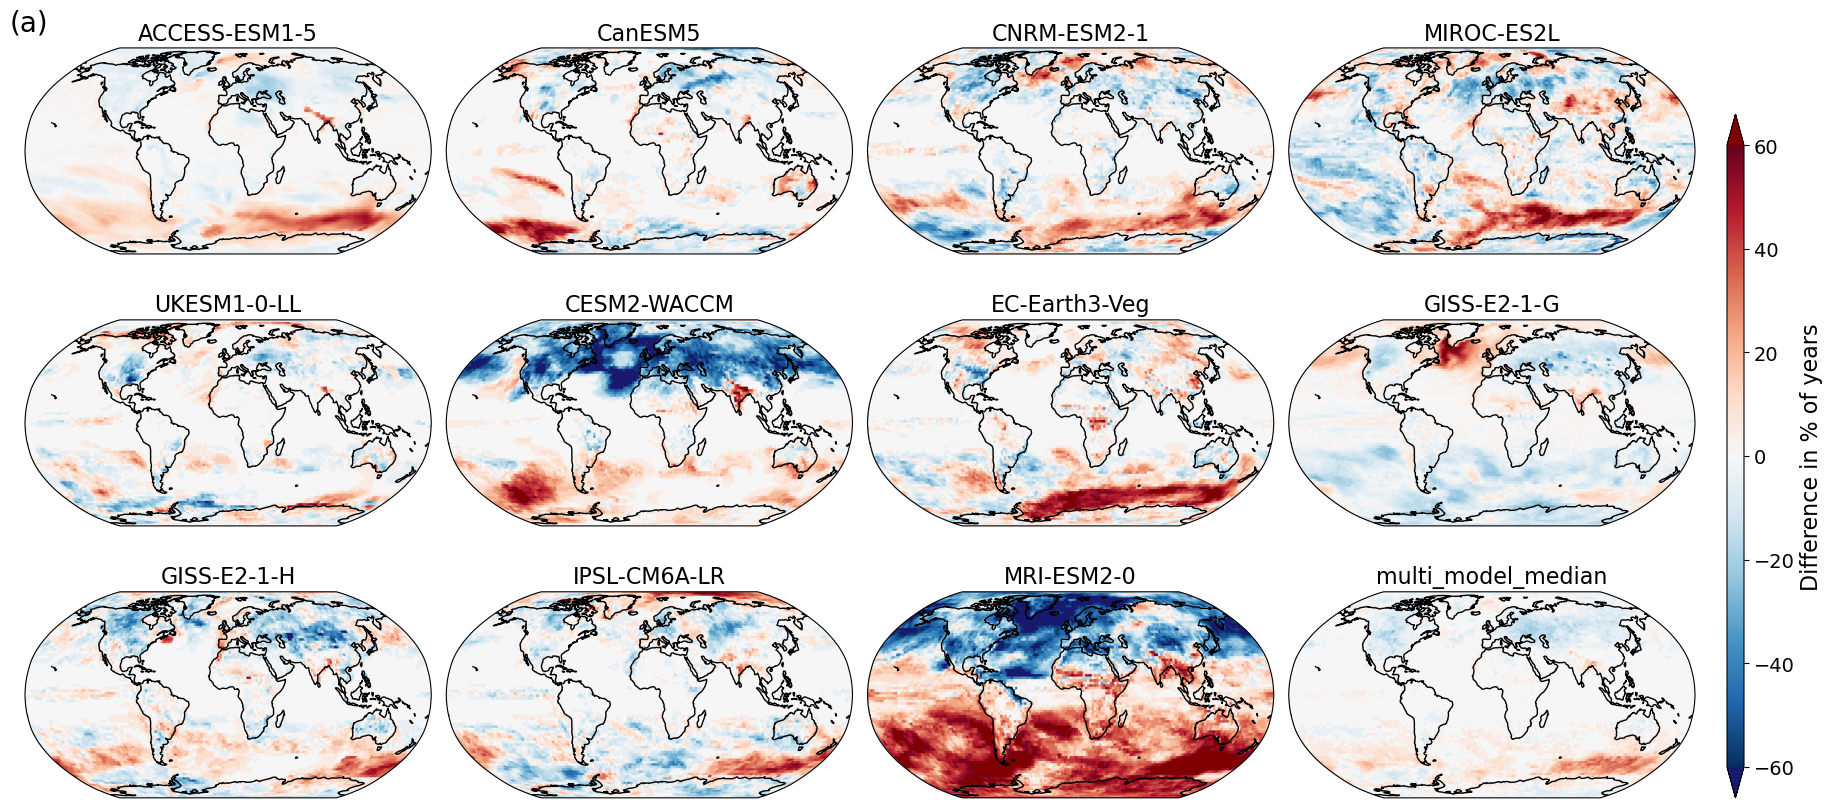

In [15]:
fig = plotting.plot_ext_freq_diff(
    differences=differences,
    expt='ssp534-over',
    ext_type='heat',
    gwl=None,
    period='matching',
    threshold='sigma1',
    levels=None,
    label='(a)',
    title='1$\sigma$',
    vmin=-60,
    vmax=60,
    exclude_models = ()
    # fig_dir=FIG_DIR,
    # folder='supplementary',
    # file_name='figure_S4a'
)